# Распознавание лиц (ноутбук)

### **Идентификация лиц: Создание системы распознавания на основе Contrastive Loss**

В этом ноутбуке мы углубимся в практическую реализацию системы идентификации лиц. Это задача, где по фотографии лица нужно определить, кто это, или подтвердить, что это именно тот человек, за которого он себя выдает. Мы будем использовать подход, основанный на **векторных представлениях (эмбеддингах)** лиц, и обучать модель так, чтобы эмбеддинги одного и того же человека были близки, а разных людей — далеки друг от друга.

Мы сосредоточимся на функции потерь **Contrastive Loss**, которая является более простой альтернативой Triplet Loss, обсуждаемой в лекции.

В этом ноутбуке мы:
1.  **Создадим собственный класс `Dataset`** для работы с набором данных лиц, который не представлен в `torchvision`. Мы научимся правильно сэмплировать пары изображений для `Contrastive Loss`.
2.  **Разработаем сверточную нейронную сеть (`ContrastiveModel`)** для извлечения эмбеддингов лиц.
3.  **Реализуем `ContrastiveLoss`** в PyTorch.
4.  **Обучим модель** на парах лиц, используя Contrastive Loss.
5.  **Разработаем метрику оценки** качества идентификации лиц, основанную на поиске ближайшего соседа в пространстве эмбеддингов.
6.  **Визуализируем работу** системы, находя ближайших и самых далеких соседей для тестовых изображений.

In [1]:
#!g1.1
# Импортируем необходимые библиотеки
import os # Для работы с файловой системой (например, os.listdir, os.path.join)
from glob import glob # Для поиска файлов по шаблону (например, '*/*')

import matplotlib.pyplot as plt # Для построения графиков и отображения изображений
import numpy as np # Для работы с массивами (особенно полезно для случайных выборок)
import torch # Основная библиотека PyTorch
import torch.nn as nn # Модули для создания нейронных сетей
import torch.optim as optim # Оптимизаторы (например, Adam)
import torchvision.transforms as T # Преобразования изображений
from IPython.display import clear_output # Для очистки вывода в Jupyter/Colab
from PIL import Image # Для работы с изображениями (Pillow)
from torch.utils.data import Dataset # Базовый класс для создания пользовательских датасетов
from torch.utils.data import DataLoader # Для загрузки данных батчами
import torch.nn.functional as F # Функции без параметров (например, pairwise_distance)
from tqdm import tqdm # Модуль для отображения хода обучения

### Создание пользовательского датасета для лиц (`Faces` Dataset)

В отличие от стандартных датасетов вроде MNIST, для лиц часто приходится
писать свой `Dataset` класс, так как структура данных может быть
специфичной. Наш датасет будет содержать папки с фотографиями разных
людей, где каждая папка соответствует одному человеку.

Основная сложность для `Contrastive Loss` заключается в правильном
сэмплировании пар изображений: нам нужны как пары одного и того же
человека (положительные примеры), так и пары разных людей (отрицательные
примеры). При случайном сэмплировании отрицательных примеров будет
подавляющее большинство, что приведет к несбалансированности обучения.
Наш `Dataset` будет сэмплировать эти пары сбалансированно.

In [2]:
#!g1.1
def _loader(path: str) -> Image.Image:
    """
    Вспомогательная функция для загрузки изображения по указанному пути.
    Конвертирует изображение в оттенки серого ('L' mode).
    """
    with open(path, 'rb') as f:
        img = Image.open(f)
        return img.convert('L') # 'L' означает 8-битное изображение в оттенках серого


class Faces(Dataset):
    """
    Пользовательский класс Dataset для набора данных лиц.
    Предназначен для создания пар изображений для Contrastive Loss.
    """
    def __init__(self, root: str, split: str = 'train', transform=None):
        """
        Инициализация датасета.
        :param root: Корневой путь к датасету (например, 'faces_dataset').
        :param split: 'train' или 'test' - указывает, какую часть датасета использовать.
        :param transform: Преобразования, которые будут применяться к изображениям.
        """
        self.root = os.path.join(root, split) # Полный путь к папке 'train' или 'test'

        # Получаем список уникальных имен (ID) людей и создаем маппинги ID <-> индекс.
        # Например, если папки называются '1', '2', ..., '40', то names будет [1, 2, ..., 40].
        # name2idx: {1:0, 2:1, ...} ; idx2name: {0:1, 1:2, ...}
        self.names, self.name2idx, self.idx2name = self._get_names()

        # Получаем все пути к изображениям и соответствующие им метки (ID людей).
        self.images, self.labels = self._get_people()
        self.total_idxs = np.arange(len(self.images)) # Массив индексов для сэмплирования

        self.transform = transform # Сохраняем переданные трансформации

    def _get_names(self):
        """
        Внутренняя вспомогательная функция для получения имен (ID) всех классов (людей)
        в текущем сплите датасета.
        """
        # os.listdir(self.root) возвращает список имен папок (строк).
        # map(lambda x: int(x), ...) преобразует их в целые числа.
        names = list(map(lambda x: int(x), os.listdir(self.root)))
        # Создаем словари для прямого и обратного маппинга (имя человека <-> числовой индекс класса).
        name2idx = {name: _ for _, name in enumerate(names)}
        idx2name = {_: name for _, name in enumerate(names)}

        return names, name2idx, idx2name

    def _get_people(self):
        """
        Внутренняя вспомогательная функция для сбора всех путей к изображениям
        и их меток (ID человека).
        """
        # glob(os.path.join(self.root, '*/*')) ищет все файлы во всех подпапках self.root.
        # Например, 'faces_dataset/train/1/image.png'
        images = glob(os.path.join(self.root, '*/*'))
        
        # Для каждого пути к изображению извлекаем ID человека.
        # image.split('/')[-2]: разделяем путь по '/' и берем предпоследний элемент,
        #                       который является названием папки с ID человека.
        # int(...): преобразуем название папки в число.
        # self.name2idx[...]: преобразуем ID человека в индекс класса.
        labels = [self.name2idx[int(os.path.basename(os.path.dirname(image)))] for image in images]

        return np.array(images), np.array(labels) # Возвращаем массивы путей и меток

    def __getitem__(self, item):
        """
        Возвращает пару изображений (image1, image2) с меткой (label),
        указывающей, один ли это человек (1) или разные (0),
        и истинную метку первого изображения (label_item).
        """
        image1_path = self.images[item]
        image1 = _loader(image1_path) # Загружаем первое изображение

        # Сэмплируем второе изображение:
        # С вероятностью 50% выбираем изображение того же человека (положительный пример).
        if np.random.uniform() < 0.5:
            # Выбираем случайное изображение из списка изображений,
            # где метка (self.labels) совпадает с меткой первого изображения (self.labels[item]).
            image2_path = np.random.choice(self.images[self.labels == self.labels[item]])
            image2 = _loader(image2_path)
            label = torch.tensor([1], dtype=torch.float) # Метка 1: тот же человек
        else: # С вероятностью 50% выбираем изображение другого человека (отрицательный пример).
            # Выбираем случайное изображение из списка изображений,
            # где метка (self.labels) НЕ совпадает с меткой первого изображения.
            image2_path = np.random.choice(self.images[self.labels != self.labels[item]])
            image2 = _loader(image2_path)
            label = torch.tensor([0], dtype=torch.float) # Метка 0: разные люди

        # Применяем трансформации, если они были заданы.
        if self.transform is not None:
            image1 = self.transform(image1)
            image2 = self.transform(image2)

        # Возвращаем первое изображение, второе изображение, метку пары (0/1),
        # и истинную метку класса для первого изображения (для оценки accuracy).
        return image1, image2, label, torch.tensor([self.labels[item]], dtype=torch.int)

    def __len__(self):
        """Возвращает общее количество изображений в датасете."""
        return len(self.images)


**Структура датасета `faces_dataset`:** Предполагается, что датасет
имеет следующую структуру:

    faces_dataset/
    +-- train/
    ¦   +-- 0/
    ¦   ¦   +-- 0_0.png
    ¦   ¦   +-- 0_1.png
    ¦   ¦   L-- ...
    ¦   +-- 1/
    ¦   ¦   +-- 1_0.png
    ¦   ¦   +-- 1_1.png
    ¦   ¦   L-- ...
    ¦   L-- ... (до 39 папок)
    L-- test/
        +-- 0/
        ¦   +-- 0_0.png
        ¦   L-- ...
        L-- ...

Каждая папка `0`, `1`, …, `39` содержит изображения одного человека.
Названия папок используются как ID людей.


In [3]:
#!g1.1
# Создаем экземпляр датасета для предварительной проверки.
dataset = Faces('faces_dataset')

In [4]:
#!g1.1
# Проверяем, что возвращает метод __getitem__ для первого элемента.
# Ожидаем: (изображение1, изображение2, метка_пары, истинная_метка_image1)
dataset[0]

(<PIL.Image.Image image mode=L size=92x112>,
 <PIL.Image.Image image mode=L size=92x112>,
 tensor([0.]),
 tensor([0], dtype=torch.int32))

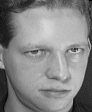

In [5]:
#!g1.1
# Отобразим первое изображение из пары.
dataset[0][0] # Это будет объект PIL Image

**Визуализация сэмплированных пар:** Посмотрим на несколько
сгенерированных пар изображений, чтобы убедиться, что логика
`__getitem__` работает правильно.

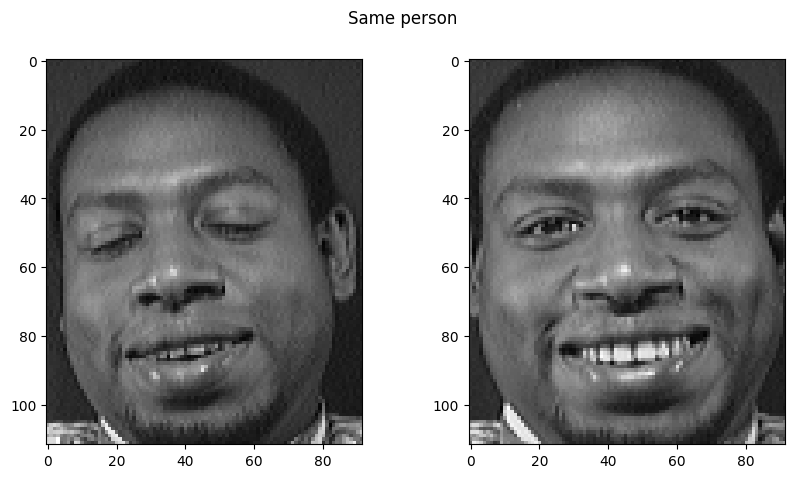

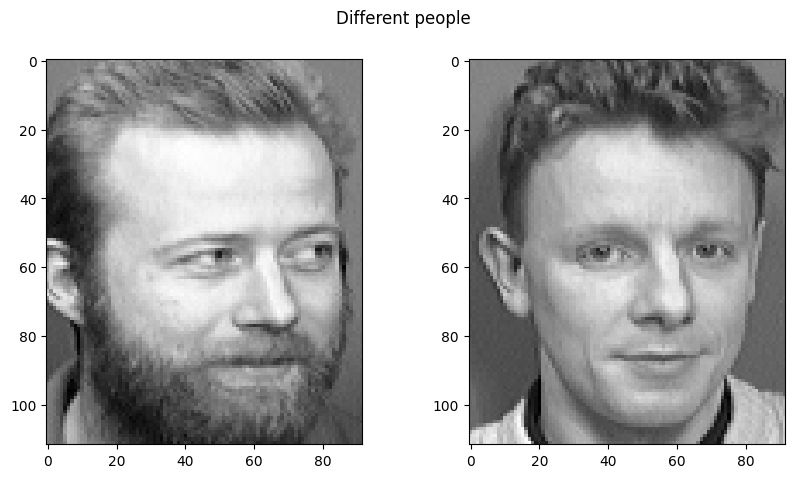

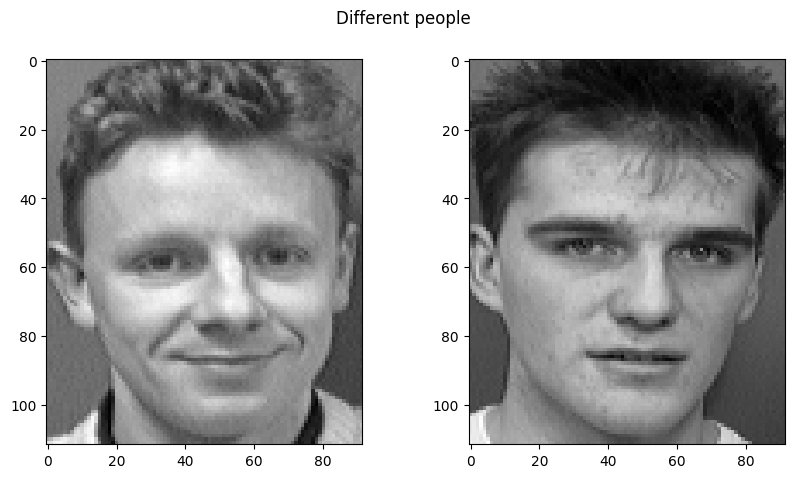

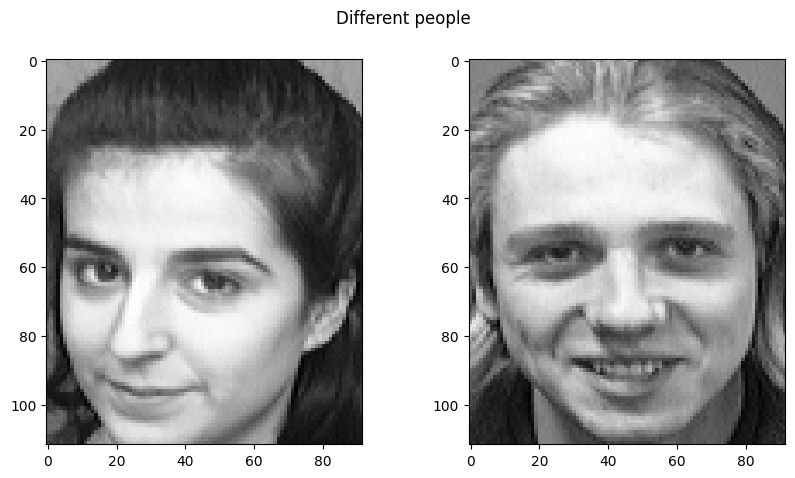

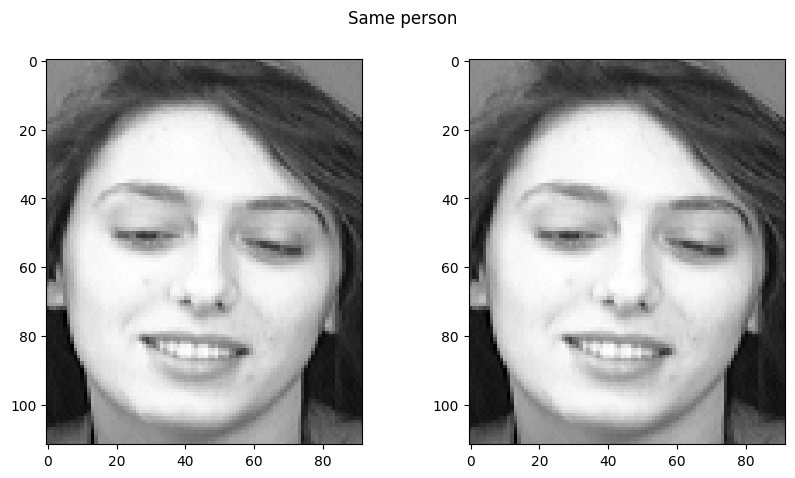

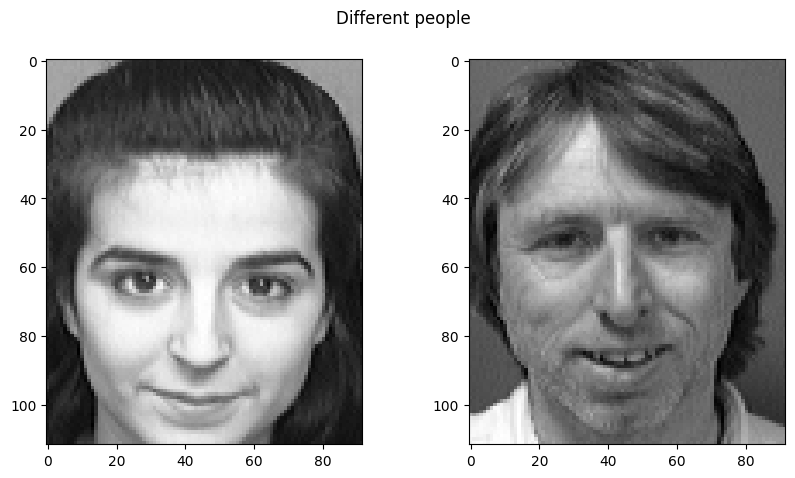

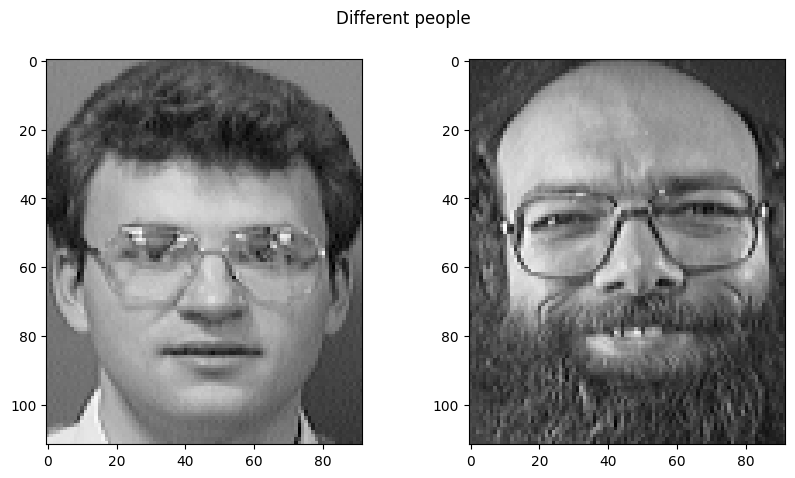

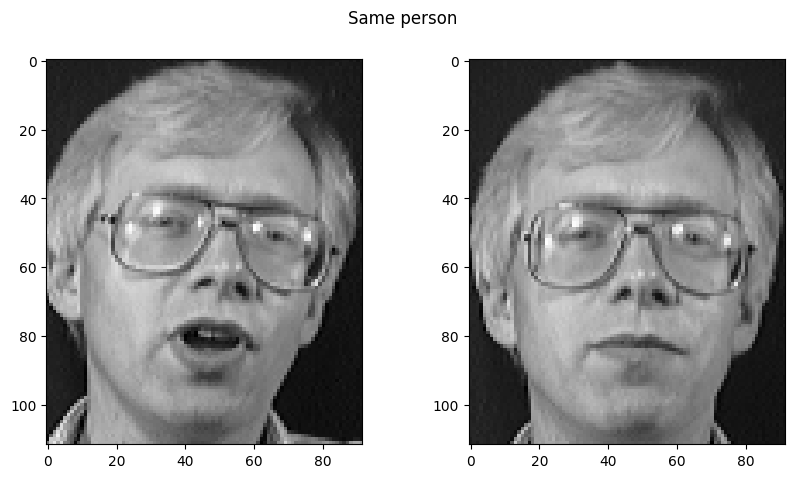

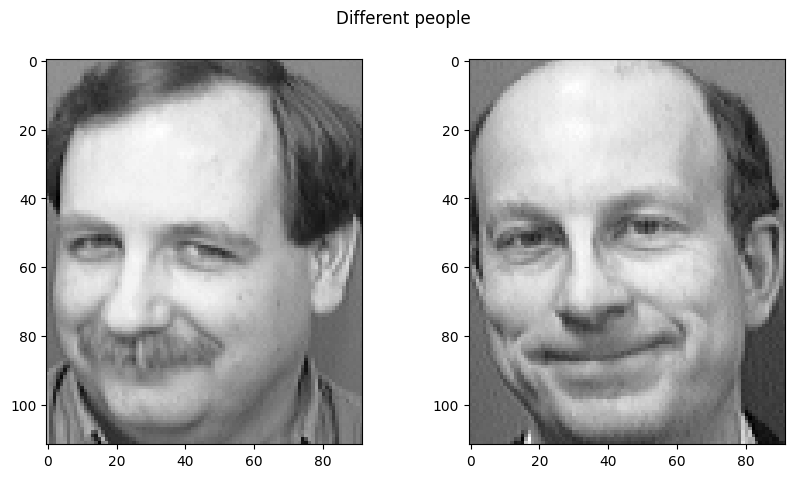

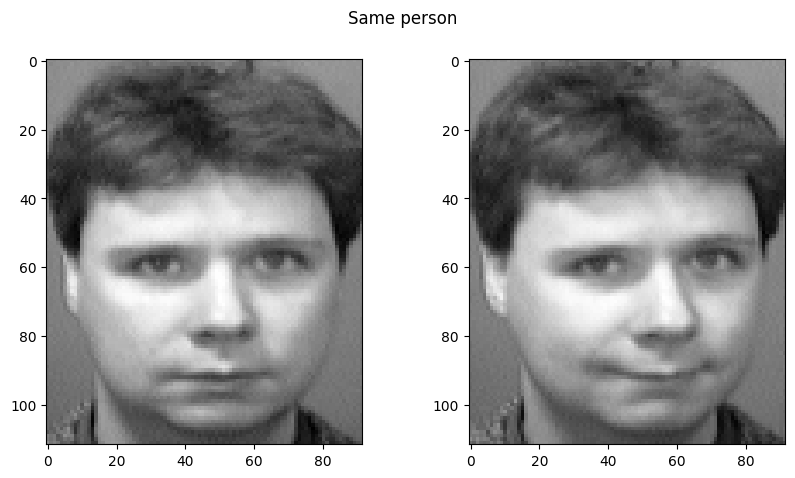

In [6]:
#!g1.1
# Выбираем 10 случайных индексов из датасета.
for i in np.random.randint(len(dataset), size=10):
    fig, ax = plt.subplots(1, 2, figsize=(10, 5)) # Создаем фигуру с двумя подграфиками
    
    img1, img2, label, _ = dataset[i] # Получаем пару изображений и метку
    
    ax[0].imshow(img1, cmap='gray') # Отображаем первое изображение
    ax[1].imshow(img2, cmap='gray') # Отображаем второе изображение
    
    # Устанавливаем заголовок фигуры в зависимости от метки пары.
    fig.suptitle('Same person' if label.item() else 'Different people')
    
    plt.show() # Показываем графики

### Преобразования данных и DataLoader’ы

Определим трансформации для изображений (изменение размера, случайное
отражение для аугментации) и создадим `DataLoader`’ы.

In [7]:
#!g1.1
# Трансформации для обучающей выборки:
train_transform = T.Compose(
    [
        T.Resize((128, 128)), # Изменяем размер до 128x128 пикселей
        T.RandomHorizontalFlip(), # Случайное горизонтальное отражение для аугментации данных
        T.ToTensor() # Преобразуем в тензор, нормализуя пиксели в [0, 1]
    ]
)

# Трансформации для тестовой (валидационной) выборки:
# Здесь не применяем аугментацию, только изменение размера и преобразование в тензор.
test_transform = T.Compose(
    [
        T.Resize((128, 128)),
        T.ToTensor()
    ]
)

In [8]:
# Создаем экземпляры датасетов с заданными трансформациями.
train_dataset = Faces('faces_dataset', 'train', transform=train_transform)
valid_dataset = Faces('faces_dataset', 'test', transform=test_transform)

In [9]:
#!g1.1
# Проверяем форму одного изображения после трансформаций.
train_dataset[0][0].shape # Ожидаем: [1, 128, 128] (1 канал, 128x128 пикселей)

torch.Size([1, 128, 128])

In [10]:
#!g1.1
# Создаем DataLoader'ы.
# train_loader: batch_size=128, shuffle=True для перемешивания данных в каждой эпохе.
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    pin_memory=True, # Ускоряет передачу данных на GPU
    shuffle=True
)

# valid_loader: batch_size=1, shuffle=False.
# batch_size=1 на валидации выбран для удобства оценки, так как мы будем сравнивать
# каждое тестовое изображение с *всеми* обучающими изображениями по отдельности.
# В реальных условиях для повышения эффективности можно использовать большие батчи
# и более продвинутые методы поиска ближайших соседей (например, FAISS).
valid_loader = DataLoader(
    valid_dataset,
    batch_size=1,
    pin_memory=True,
    shuffle=False
)

# Количество батчей в обучающем загрузчике.
# Поскольку датасет небольшой, батчей всего 3.
len(train_loader)

3

### Contrastive Loss: Функция потерь для обучения эмбеддингам

Мы реализуем `Contrastive Loss`, как обсуждалось в лекции. Эта функция
потерь стремится минимизировать расстояние между эмбеддингами
изображений одного человека и максимизировать расстояние (до
определенной границы, `margin`) между эмбеддингами разных людей.

**Формула Contrastive Loss:**
$L = Y \cdot D^2 + (1 - Y) \cdot \max(0, \text{margin} - D)^2$ Где: \*
$Y$: метка пары (1, если один человек; 0, если разные люди). \* $D$:
Евклидово расстояние между двумя эмбеддингами. \* $\text{margin}$:
гиперпараметр, определяющий минимальное желаемое расстояние между
эмбеддингами разных людей.

**Как работает:** \* **Если $Y=1$ (один человек):** $L = D^2$. Модель
штрафуется пропорционально квадрату расстояния между эмбеддингами. Цель:
сделать $D$ как можно меньше (сблизить эмбеддинги). \* **Если $Y=0$
(разные люди):** $L = \max(0, \text{margin} - D)^2$. Модель штрафуется,
если расстояние $D$ *меньше* `margin`. Если $D$ уже больше `margin`, то
$\text{margin} - D$ будет отрицательным, $\max(0, \text{negative})$
станет 0, и штраф не будет налагаться. Цель: раздвинуть эмбеддинги
разных людей на расстояние не меньше `margin`.

In [11]:
#!g1.1
class ContrastiveLoss(torch.nn.Module):
    def __init__(self, margin=2.0):
        super().__init__()
        self.margin = margin # Гиперпараметр - граница для негативных пар

    def forward(self, x1, x2, y):
        # F.pairwise_distance вычисляет Евклидово расстояние между каждым вектором в x1
        # и соответствующим вектором в x2.
        # keepdim=True сохраняет размерность, чтобы результат был [batch_size, 1].
        dist = F.pairwise_distance(x1, x2, keepdim = True)

        # Вычисляем Contrastive Loss согласно формуле:
        # y * torch.pow(dist, 2): Штраф для положительных пар (y=1) - квадрат расстояния.
        # (1 - y) * torch.pow(torch.clamp(self.margin - dist, min=0.0), 2):
        #   Штраф для негативных пар (y=0) - квадрат max(0, margin - dist).
        #   torch.clamp(..., min=0.0) обрезает отрицательные значения до нуля,
        #   реализуя часть max(0, ...) в формуле.
        return torch.mean( # Усредняем ошибку по всему батчу
            y * torch.pow(dist, 2) +
            (1 - y) * torch.pow(torch.clamp(self.margin - dist, min=0.0), 2)
        )

### Архитектура нейронной сети для эмбеддингов (`ContrastiveModel`)

Модель будет состоять из двух частей: 1. **`feature_extractor`**:
Сверточная часть для извлечения признаков из входного изображения. Она
будет использовать `Conv2d`, `BatchNorm2d`, `LeakyReLU` и `MaxPool2d`
для последовательного уменьшения пространственного размера и увеличения
глубины признаковых карт. 2. **`fc` (fully connected)**: Полносвязная
часть, которая преобразует плоские признаки из `feature_extractor` в
конечный вектор эмбеддинга (в нашем случае, размерностью 10).

In [12]:
#!g1.1
class ContrastiveModel(nn.Module):
    def __init__(self):
        super().__init__()

        # --- Feature Extractor (сверточная часть) ---
        # Эта часть извлекает иерархические признаки из изображения.
        # Вход: [batch_size, 1, 128, 128]
        self.feature_extractor = nn.Sequential(
            # Блок 1: Conv -> BatchNorm -> LeakyReLU -> MaxPool
            nn.Conv2d(1, 32, kernel_size=3, padding=1), # Вход 1 канал (grayscale), выход 32 канала
            nn.BatchNorm2d(32), # Нормализация
            nn.LeakyReLU(), # Активация
            
            nn.MaxPool2d(2),  # Уменьшение размера до 64x64
            
            # Блок 2: Conv -> BatchNorm -> LeakyReLU -> MaxPool
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(),
            
            nn.MaxPool2d(2),  # Уменьшение размера до 32x32
            
            # Блок 3: Conv -> BatchNorm -> LeakyReLU -> MaxPool
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(),
            
            nn.MaxPool2d(2),  # Уменьшение размера до 16x16
            
            nn.Flatten() # Вытягиваем 3D тензор [batch_size, 32, 16, 16] в 1D вектор [batch_size, 32 * 16 * 16]
                         # 32 * 16 * 16 = 8192 признака
        )

        # --- Fully Connected (полносвязная часть) ---
        # Эта часть преобразует извлеченные признаки в финальный эмбеддинг.
        self.fc = nn.Sequential(
            nn.Linear(16 * 16 * 32, 512), # Из 8192 признаков в 512
            nn.ReLU(), # Активация
            nn.Linear(512, 10) # Из 512 признаков в 10-мерный вектор эмбеддинга
                               # Размерность 10 выбрана для демонстрации;
                               # в реальных задачах она обычно больше (например, 128, 256, 512).
        )

    def forward_single(self, x):
        """
        Прямой проход для одного изображения. Возвращает его эмбеддинг.
        """
        return self.fc(self.feature_extractor(x))

    def forward(self, x1, x2):
        """
        Прямой проход для пары изображений. Возвращает кортеж из двух эмбеддингов.
        """
        return self.forward_single(x1), self.forward_single(x2)

In [13]:
#!g1.1
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

print("Используемое устройство:", device)
if torch.cuda.is_available():
    print("Имя GPU:", torch.cuda.get_device_name())

Используемое устройство: cuda:0
Имя GPU: NVIDIA GeForce RTX 4060 Ti



### Вспомогательные функции для обучения и оценки

Мы адаптируем стандартные функции `train`, `evaluate` и `plot_stats` под
специфику обучения с `Contrastive Loss`. Также добавим функцию
`get_latent_base` для сбора всех эмбеддингов обучающей выборки, что
понадобится для оценки качества.

#### `train(model, optimizer, loader, loss_fn)`: Функция для одной эпохи обучения


In [14]:
#!g1.1
def train(model, optimizer, loader, loss_fn) -> float:
    model.train() # Переводим модель в режим обучения

    train_loss = 0 # Общая ошибка за эпоху

    # Итерируемся по DataLoader'у, получаем x1, x2 (пара изображений),
    # y (метка пары: 0/1), и _ (истинная метка x1, которую здесь не используем).
    for x1, x2, y, _ in tqdm(loader, desc='Train'):
        # Перемещаем все тензоры на устройство (GPU/CPU)
        x1, x2, y = x1.to(device), x2.to(device), y.to(device)

        optimizer.zero_grad() # Обнуляем градиенты

        # Пропускаем пару изображений через модель для получения эмбеддингов.
        output1, output2 = model(x1, x2)

        # Вычисляем Contrastive Loss.
        loss = loss_fn(output1, output2, y)

        loss.backward() # Обратное распространение ошибки
        
        train_loss += loss.item() # Накопление ошибки

        optimizer.step() # Обновление весов

    train_loss /= len(train_loader) # Усреднение ошибки
    return train_loss


#### `get_latent_base(model)`: Функция для сбора эмбеддингов обучающей выборки

Для оценки качества идентификации нам понадобится база данных всех
эмбеддингов и их истинных меток для обучающих изображений.

In [15]:
#!g1.1
@torch.inference_mode()
def get_latent_base(model):
    """
    Собирает все изображения, их истинные метки и их эмбеддинги
    из обучающей выборки, используя текущую модель.
    """
    model.eval() # Переводим модель в режим оценки

    xs = [] # Список для хранения исходных изображений
    ys = [] # Список для хранения истинных меток
    zs = [] # Список для хранения эмбеддингов

    # Итерируемся по train_loader. Обрати внимание, что здесь мы используем x (одно изображение) и y (его метку),
    # а x1, x2, _ игнорируем, поскольку нам нужны исходные данные и их метки для создания базы.
    for x, _, _, y in train_loader:
        # Получаем эмбеддинг для одного изображения x.
        z = model.forward_single(x.to(device))

        xs.append(x.cpu()) # Сохраняем изображения на CPU
        ys.append(y) # Сохраняем метки
        zs.append(z) # Сохраняем эмбеддинги

    # Объединяем все тензоры из списков.
    xs = torch.cat(xs)
    ys = torch.cat(ys)
    zs = torch.cat(zs)
    
    return xs, ys, zs # Возвращаем базу изображений, меток и эмбеддингов


#### `evaluate(model)`: Функция для оценки качества идентификации

Качество идентификации будет оцениваться по следующему принципу: для
каждого тестового изображения мы находим *ближайшего соседа* в
пространстве эмбеддингов среди *всех* обучающих изображений. Если метка
ближайшего соседа совпадает с истинной меткой тестового изображения, то
идентификация считается успешной.

In [16]:
#!g1.1
@torch.inference_mode()
def evaluate(model):
    """
    Оценивает точность идентификации лиц, используя подход ближайшего соседа
    в латентном пространстве.
    """
    model.eval() # Переводим модель в режим оценки
    
    # Получаем базу данных (изображения, метки, эмбеддинги) из обучающей выборки.
    xs_train_base, ys_train_base, zs_train_base = get_latent_base(model)
    
    total = 0 # Общее количество тестовых изображений
    correct = 0 # Количество правильно идентифицированных изображений

    # Итерируемся по валидационному DataLoader'у.
    # Здесь x - одно тестовое изображение, y - его истинная метка.
    # x1, x2, _ игнорируем, так как valid_loader настроен на выдачу пар,
    # но для оценки ближайшего соседа нам нужно только одно тестовое изображение.
    for i, (x, _, _, y) in tqdm(enumerate(valid_loader), desc='Evaluation'):
        # Получаем эмбеддинг для текущего тестового изображения.
        z_test = model.forward_single(x.to(device))

        # Вычисляем Евклидово расстояние от тестового эмбеддинга (z_test)
        # до *всех* эмбеддингов из обучающей базы (zs_train_base).
        # F.pairwise_distance работает между тензором размера [1, latent_dim] и [N, latent_dim],
        # возвращая [N] расстояний.
        dists = F.pairwise_distance(z_test, zs_train_base)

        # Находим индекс эмбеддинга в обучающей базе, который находится ближе всего к тестовому.
        idx_closest = torch.argmin(dists)

        # Проверяем, совпадает ли истинная метка ближайшего соседа
        # с истинной меткой тестового изображения.
        correct += ys_train_base[idx_closest].item() == y.item()
        total += 1

    return correct / total # Возвращаем точность (долю правильных идентификаций)


#### `plot_stats(train_loss, test_accuracy, title)`: Функция для построения графиков


In [17]:
#!g1.1
def plot_stats(
    train_loss: list[float],
    test_accuracy: list[float],
    title: str
):
    plt.figure(figsize=(16, 8))
    plt.title(title + ' loss')
    plt.plot(train_loss, label='Train loss')
    plt.legend()
    plt.grid()
    plt.show()
    
    plt.figure(figsize=(16, 8))
    plt.title(title + ' accuracy')
    plt.plot(test_accuracy, label='Test accuracy')
    plt.legend()
    plt.grid()
    plt.show()

#### `train_cycle(model, optimizer, loss_fn, num_epochs, title)`: Основной цикл обучения и оценки

In [18]:
#!g1.1
def train_cycle(model, optimizer, loss_fn, num_epochs, title):
    train_loss_history, test_accuracy_history = [], [] # Списки для истории потерь и точности

    for epoch in range(num_epochs):
        print(f"Epoch {epoch + 1}/{num_epochs}")
        train_loss = train(model, optimizer, train_loader, loss_fn) # Обучение
        test_accuracy = evaluate(model) # Оценка

        train_loss_history.append(train_loss)
        test_accuracy_history.append(test_accuracy)

        # Шаг планировщика скорости обучения.
        # ReduceLROnPlateau будет уменьшать LR, если обучающая ошибка не улучшается.
        lr_shed.step(train_loss)

        clear_output(wait=True) # Очищаем вывод для обновления графиков

        plot_stats(
            train_loss_history, test_accuracy_history,
            title
        )

### Настройка и запуск обучения модели для распознавания лиц

Инициализируем модель, оптимизатор, функцию потерь и планировщик
скорости обучения.

In [19]:
#!g1.1
model = ContrastiveModel().to(device) # Создаем модель и перемещаем на GPU

optimizer = optim.Adam(model.parameters(), lr=1e-3) # Оптимизатор Adam

loss_fn = ContrastiveLoss(margin=2.0) # Contrastive Loss с маржой 2.0

# Планировщик скорости обучения ReduceLROnPlateau:
# Уменьшает скорость обучения (factor=0.5) если обучающая ошибка (monitor=train_loss)
# не уменьшается в течение 5 эпох (patience=5).
# Это помогает модели стабилизироваться и точнее настроить веса, когда обучение замедляется.
lr_shed = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
# mode='min': отслеживать уменьшение метрики (в данном случае loss).

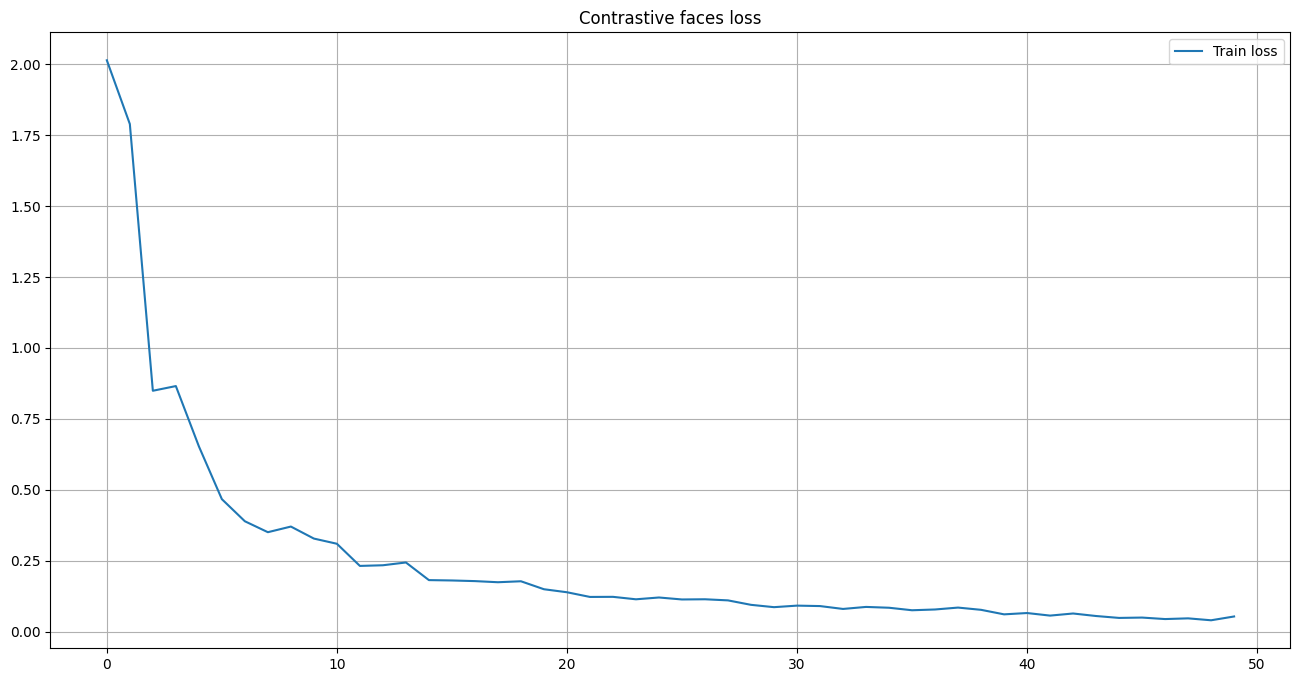

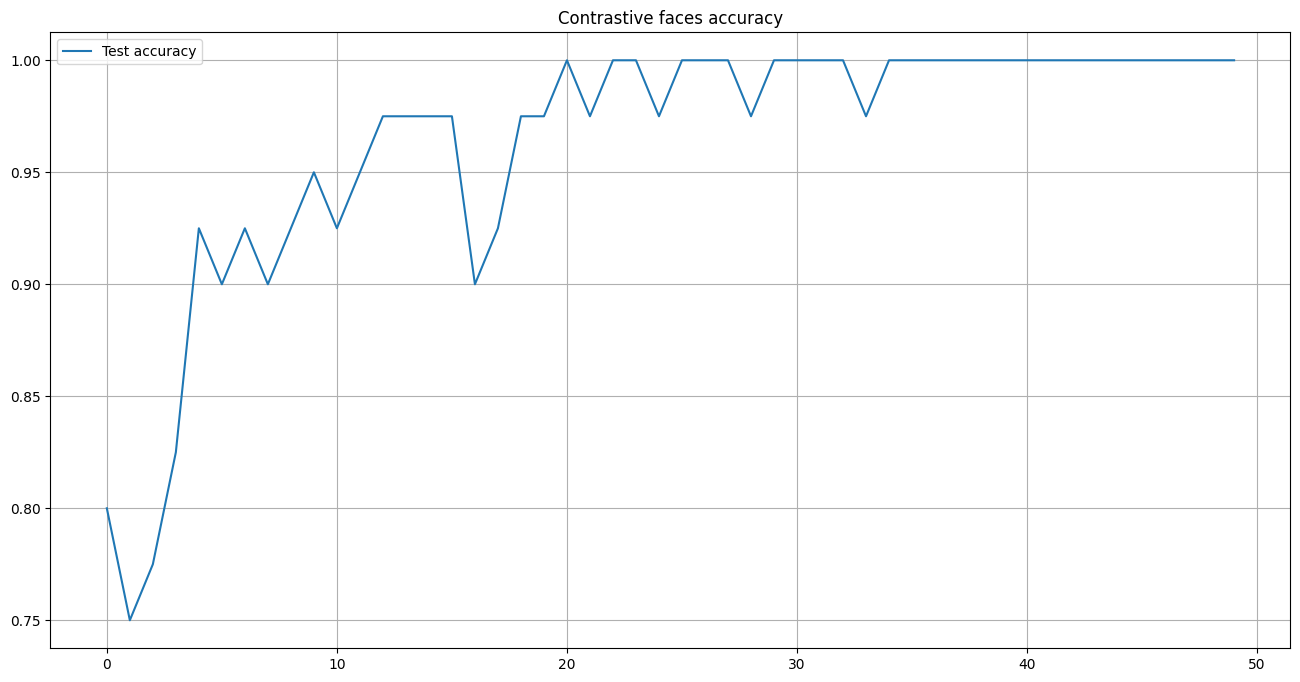

In [20]:
#!g1.1
# Запускаем полный цикл обучения на 50 эпох.
train_cycle(model, optimizer, loss_fn, 50, 'Contrastive faces')

**Анализ результатов обучения:** На графиках видно, что `Train loss`
быстро уменьшается, а `Test accuracy` значительно растет, достигая очень
высоких значений (близких к 100%). Это показывает, что модель успешно
научилась создавать эмбеддинги, которые хорошо различают лица разных
людей и сближают лица одного и того же человека. `ReduceLROnPlateau`
также мог сработать, уменьшив скорость обучения, когда потери перестали
значительно снижаться, что способствовало дальнейшему уточнению модели.

### Визуализация результатов идентификации

Давайте посмотрим на конкретные примеры. Для нескольких случайных
тестовых изображений мы найдем не только ближайшего соседа из обучающей
выборки, но и самого далекого, чтобы оценить, насколько хорошо модель
организует латентное пространство.

In [21]:
#!g1.1
# Получаем всю базу данных для обучения (изображения, метки, эмбеддинги).
xs_train_base, ys_train_base, zs_train_base = get_latent_base(model)

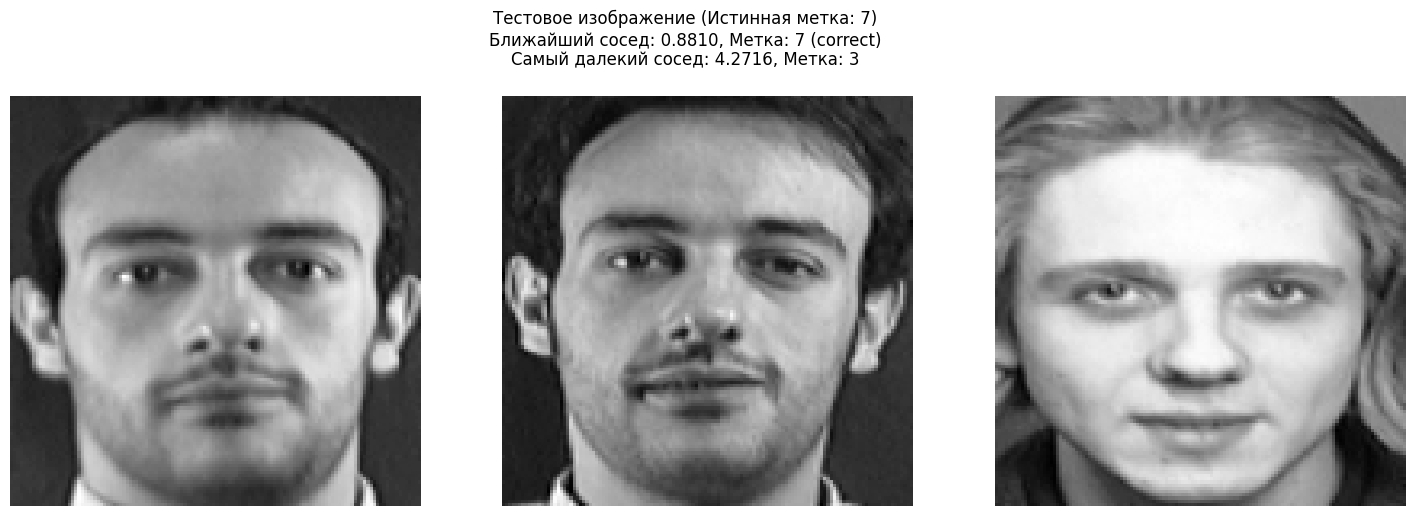

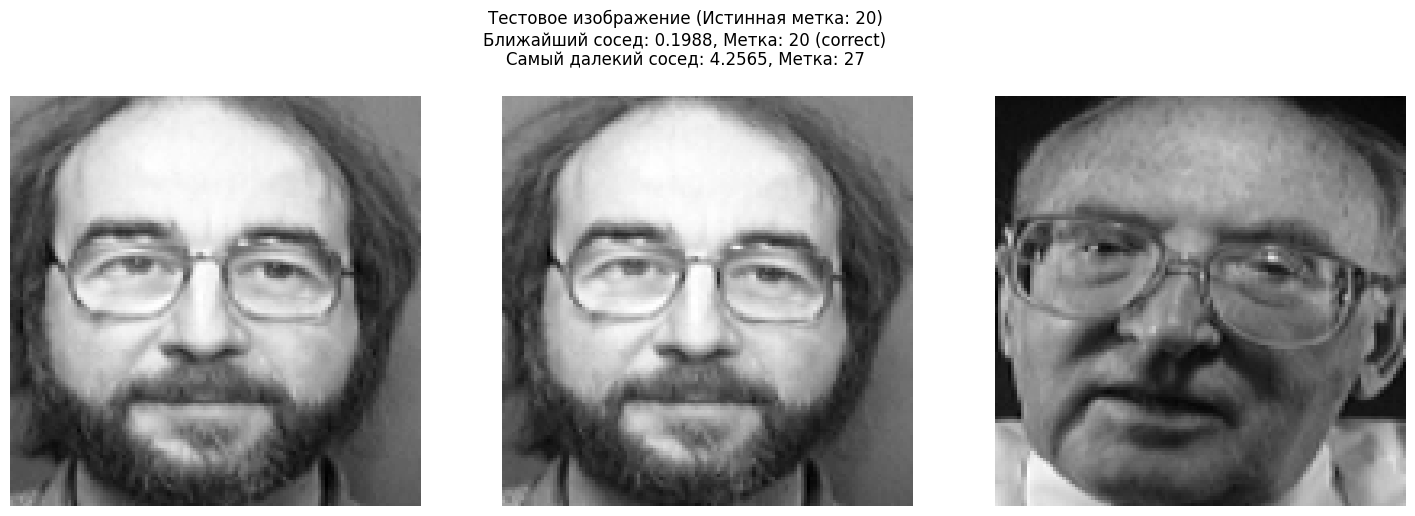

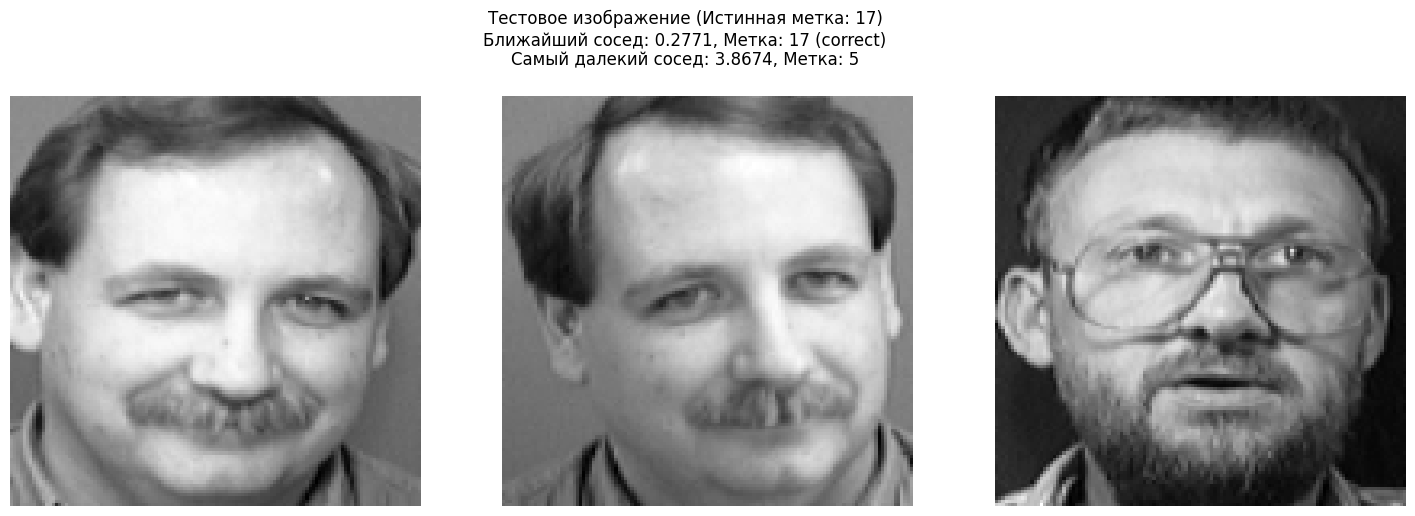

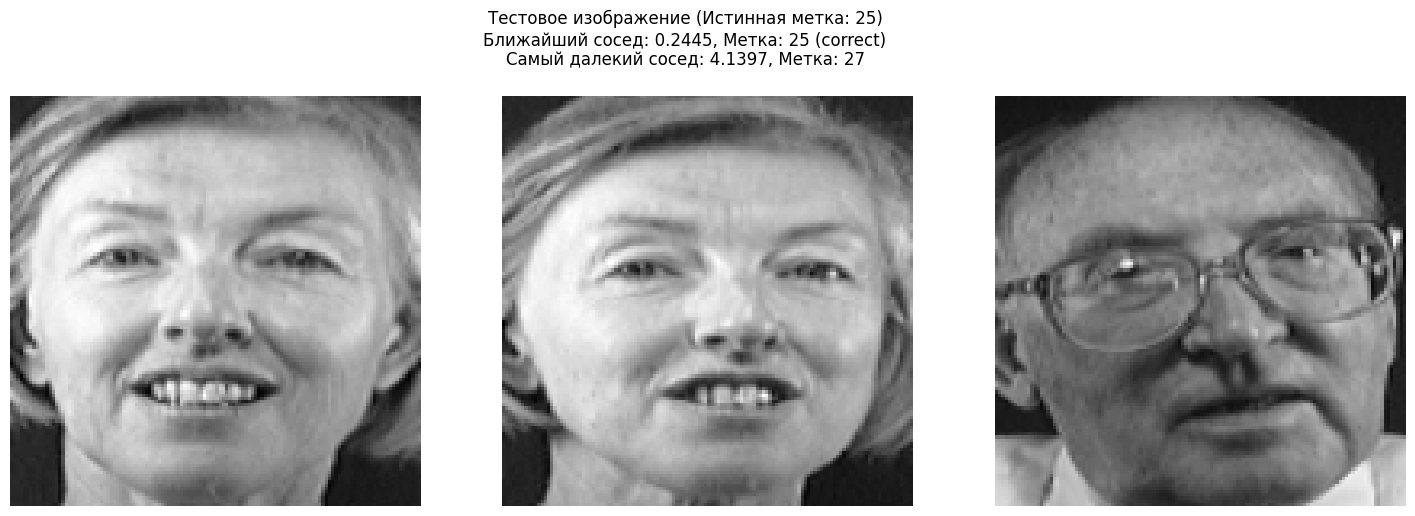

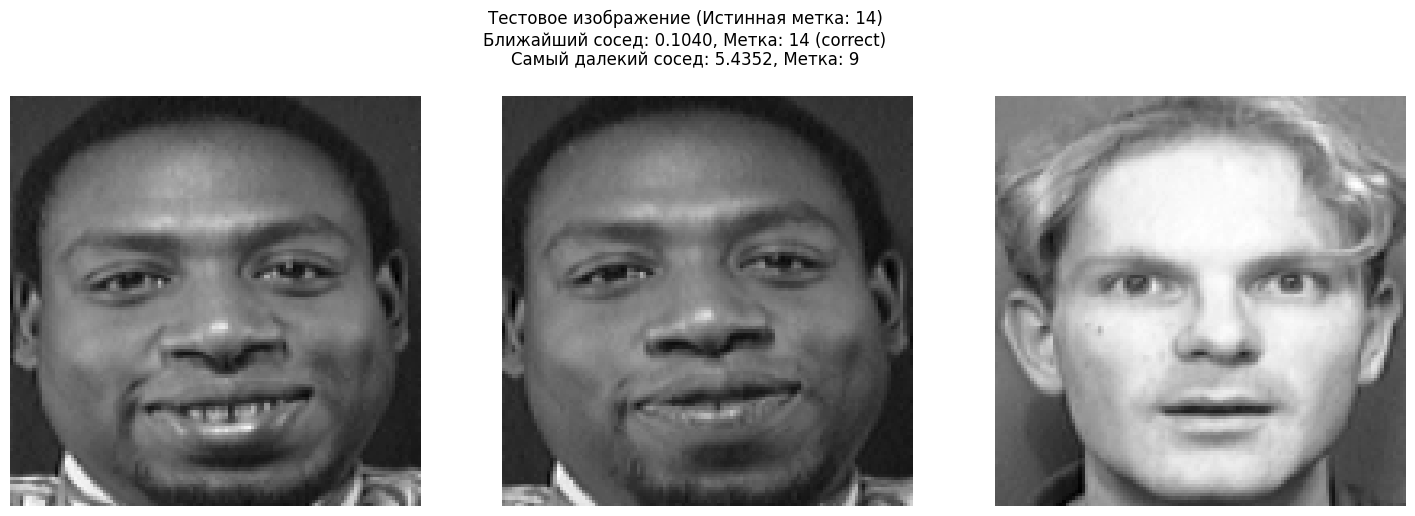

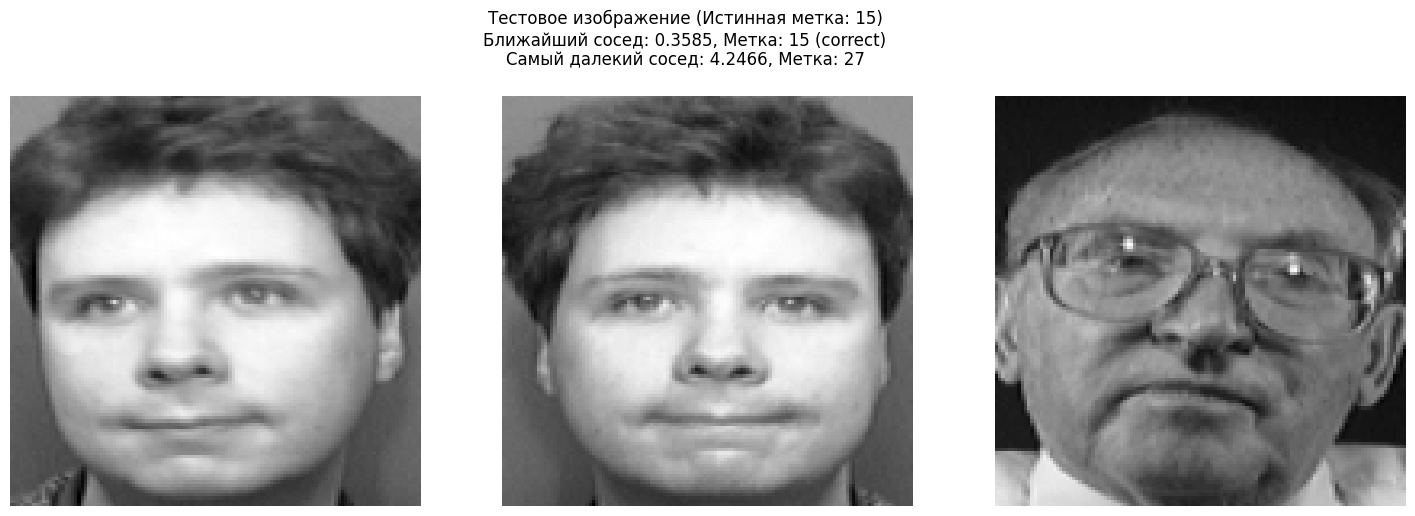

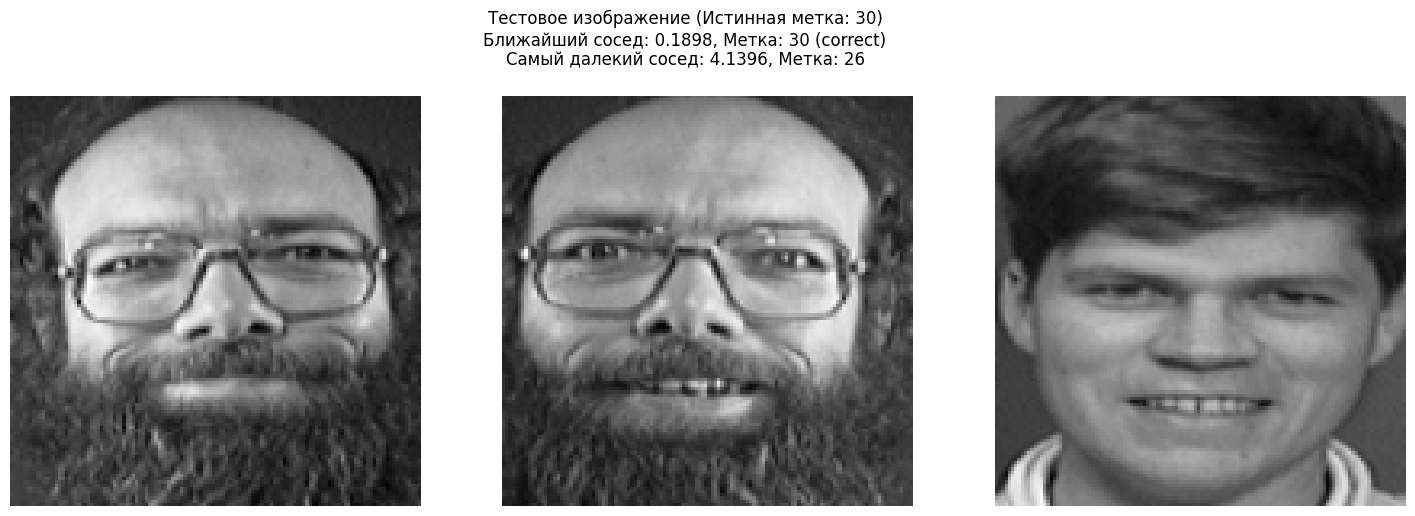

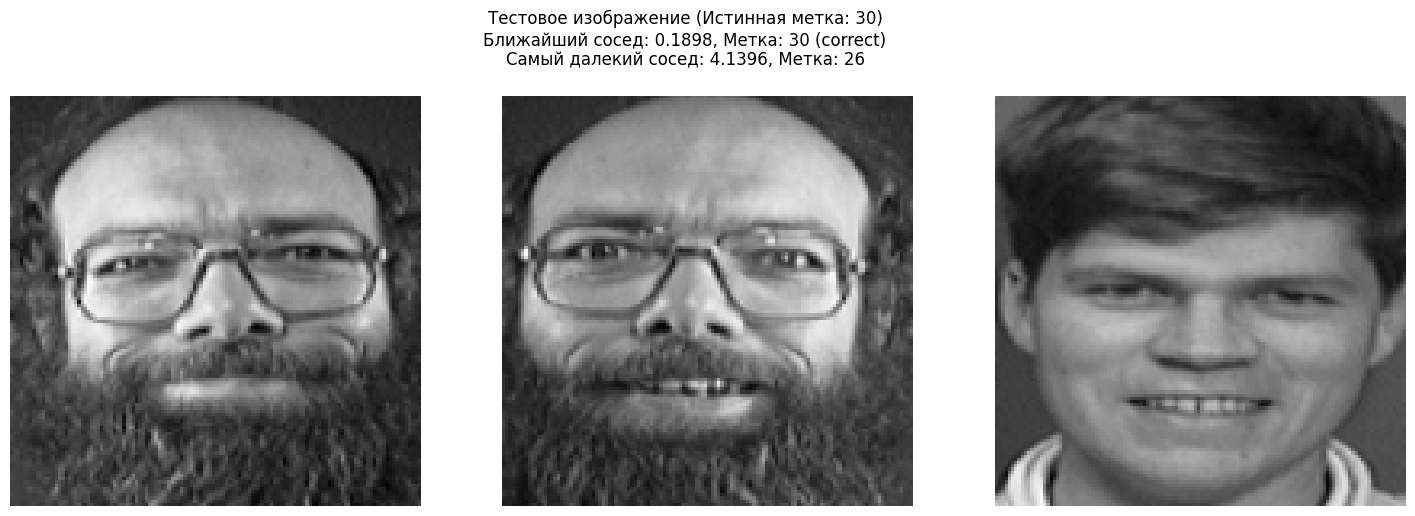

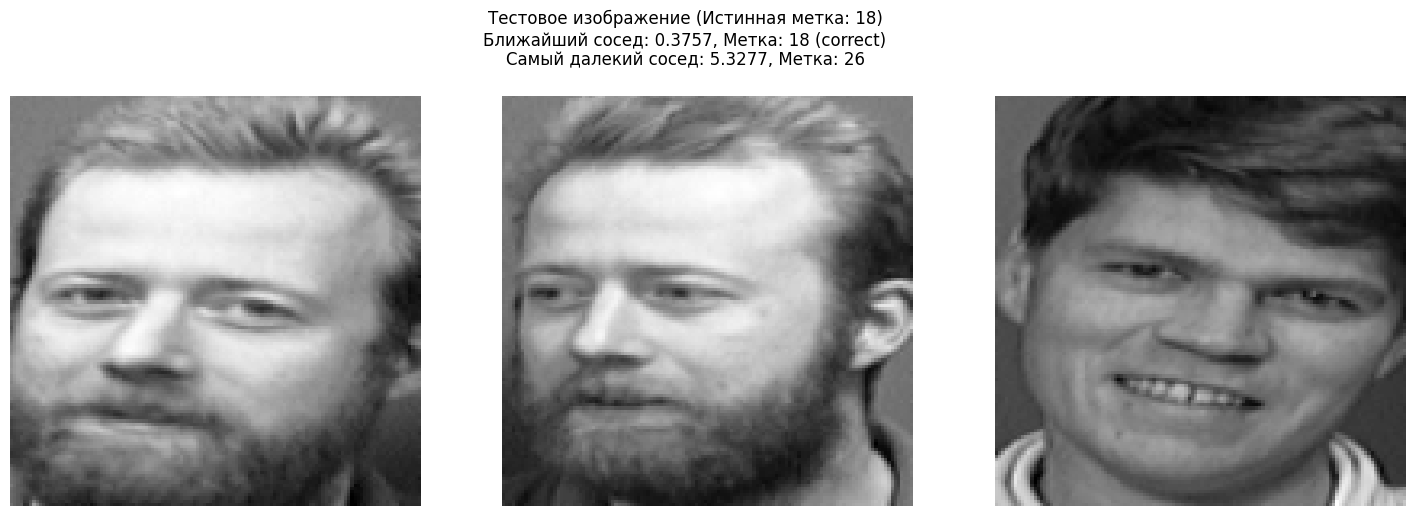

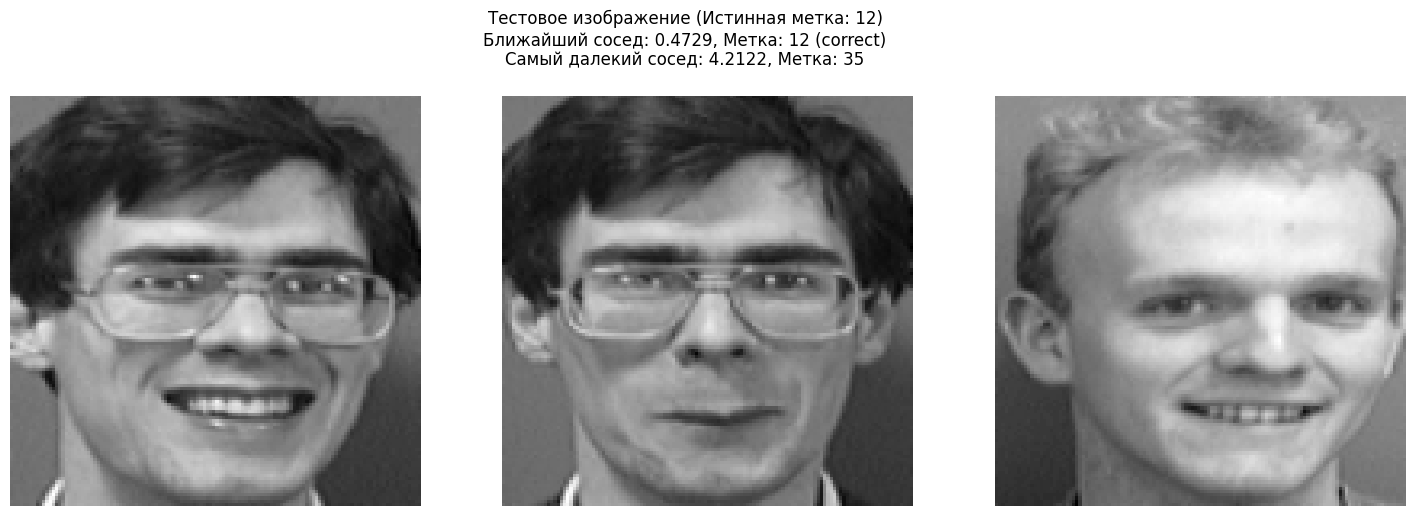

In [22]:
#!g1.1
model.eval() # Переводим модель в режим оценки

to_pil = T.ToPILImage() # Преобразователь тензора в PIL Image

# Выбираем 10 случайных изображений из валидационного датасета для визуализации.
for i in np.random.randint(len(valid_dataset), size=10):
    # Получаем одно тестовое изображение и его истинную метку.
    x_test, _, _, label_test = valid_dataset[i]

    with torch.inference_mode(): # Отключаем вычисление градиентов
        # Получаем эмбеддинг тестового изображения.
        z_test = model.forward_single(x_test.unsqueeze(0).to(device))

    fig, ax = plt.subplots(1, 3, figsize=(18, 6)) # Создаем фигуру с тремя подграфиками

    # Вычисляем расстояния от тестового эмбеддинга до всех эмбеддингов в обучающей базе.
    dists = F.pairwise_distance(z_test, zs_train_base)

    # Находим индексы ближайшего и самого далекого эмбеддингов.
    idx_closest = torch.argmin(dists)
    idx_farthest = torch.argmax(dists)

    # Отображаем:
    # ax[0]: Тестовое изображение.
    # ax[1]: Изображение ближайшего соседа из обучающей выборки.
    # ax[2]: Изображение самого далекого соседа из обучающей выборки.
    ax[0].imshow(to_pil(x_test), cmap='gray')
    ax[1].imshow(to_pil(xs_train_base[idx_closest]), cmap='gray')
    ax[2].imshow(to_pil(xs_train_base[idx_farthest]), cmap='gray')

    # Отключаем оси для всех подграфиков.
    ax[0].axis('off')
    ax[1].axis('off')
    ax[2].axis('off')

    # Устанавливаем заголовок с информацией о расстояниях и корректности идентификации.
    fig.suptitle(f'Тестовое изображение (Истинная метка: {label_test.item()})\n'
                 f'Ближайший сосед: {dists[idx_closest].item():.4f}, Метка: {ys_train_base[idx_closest].item()} ({ "correct" if ys_train_base[idx_closest].item() == label_test.item() else "incorrect"})\n'
                 f'Самый далекий сосед: {dists[idx_farthest].item():.4f}, Метка: {ys_train_base[idx_farthest].item()}')

    plt.show() # Показываем фигуру

**Выводы из визуализации:** Визуализация подтверждает высокую
эффективность нашей системы. В большинстве случаев ближайший сосед к
тестовому изображению действительно является фотографией того же
человека, что демонстрирует успешную идентификацию. Расстояние до
ближайшего соседа обычно очень мало, в то время как расстояние до самого
далекого соседа значительно больше, что указывает на хорошо
структурированное латентное пространство. В тех редких случаях, когда
идентификация “incorrect”, это может быть связано с особой позой,
освещением или просто похожими чертами лица разных людей. Такая система
с высокой точностью может быть использована для контроля доступа,
автоматической разметки фотографий или других задач распознавания лиц.